## Lung cancer

In [1]:
import pandas as pd
import os

In [2]:
# 加载数据集
file_path = '../ELIFE pancancer ready-to-use data.csv'
data = pd.read_csv(file_path)

In [3]:
positive_samples = data[data['Diagnosis'] == "Lung cancer"]
negative_samples = data[data['Label'] == 0]

num_negative = len(positive_samples) * 2  # 负样本数量是正样本的 1 倍
negative_samples = negative_samples.sample(n=num_negative, random_state=42)  # 随机采样负样本
positive_samples_upsampled = positive_samples.sample(n=len(positive_samples)*2, replace=True, random_state=42)

# 合并正负样本
Lung_sample = pd.concat([positive_samples_upsampled, negative_samples], ignore_index=True)
Lung_sample = Lung_sample.drop(columns=["SampleID", "Cohort", "Diagnosis"])
Lung_sample.to_csv("Lung_sample.csv", index=False)

In [4]:
Lung_data = pd.read_csv("Lung_sample.csv")
Lung_data

,Label,TMD_1,TMD_2,TMD_3,TMD_4,TMD_5,TMD_6,TMD_7,TMD_8,TMD_9,...,MOTIF_END_TTCG,MOTIF_END_TTCT,MOTIF_END_TTGA,MOTIF_END_TTGC,MOTIF_END_TTGG,MOTIF_END_TTGT,MOTIF_END_TTTA,MOTIF_END_TTTC,MOTIF_END_TTTG,MOTIF_END_TTTT
0,1,0.929032,0.030000,0.152913,0.076485,0.905941,0.971154,0.975000,0.321951,0.140893,...,0.000367,0.004660,0.003993,0.002578,0.003351,0.003704,0.006104,0.004989,0.004772,0.008853
1,1,0.974886,0.122137,0.011706,0.079646,0.905263,0.870370,0.968750,0.186508,0.163717,...,0.000399,0.004629,0.004133,0.002575,0.003541,0.003727,0.005714,0.004709,0.004863,0.008291
2,1,0.932238,0.044614,0.086856,0.066392,0.953390,0.918033,0.887640,0.577114,0.296610,...,0.000378,0.004562,0.004133,0.002609,0.003393,0.003784,0.006181,0.004957,0.004812,0.008873
3,1,0.938726,0.070671,0.084065,0.090153,0.903846,0.931507,1.000000,0.395161,0.272727,...,0.000366,0.004294,0.003899,0.002414,0.003234,0.003398,0.005868,0.004648,0.004548,0.007954
4,1,0.957295,0.059387,0.041667,0.104208,0.917031,0.941748,0.941176,0.093750,0.136519,...,0.000405,0.004590,0.003846,0.002516,0.003351,0.003597,0.005764,0.004894,0.004691,0.008428
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
539,0,0.960000,0.117647,0.171429,0.000000,1.000000,0.803922,1.000000,0.127660,0.062500,...,0.000395,0.004391,0.003857,0.002596,0.003415,0.003579,0.005516,0.004793,0.004704,0.008187
540,0,0.958333,0.292308,0.039216,0.031447,0.968750,0.960000,1.000000,0.416149,0.465116,...,0.000395,0.004561,0.003951,0.002638,0.003443,0.003795,0.005639,0.004932,0.004813,0.008728
541,0,0.928571,0.079304,0.018583,0.041038,0.964158,0.953846,0.962963,0.320359,0.156682,...,0.000424,0.004850,0.004195,0.002712,0.003412,0.003881,0.006281,0.005212,0.005078,0.009163
542,0,0.963303,0.000000,0.068410,0.081490,0.959016,0.935897,0.733333,0.319328,0.101266,...,0.000412,0.004570,0.004017,0.002632,0.003469,0.003722,0.006022,0.005065,0.004820,0.008877


### Fscore

In [5]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "Lung_sample_FscoreSorted.csv"
data = pd.read_csv(file_path)

In [6]:
data

,class,CNA_1:121000001-122000000,MOTIF_END_TCTG,MOTIF_END_CCCA,MOTIF_END_TAGA,MOTIF_END_CCCC,MOTIF_END_TCCC,MOTIF_END_CCCT,MOTIF_END_CCTG,MOTIF_END_TGCC,...,GWMD_chr13_35,GWMD_chr18_25,GWMD_chr4_75,GWFP_long_10:75000001-80000000,GWMD_chr10_29,GWMD_chr1_121,CNA_5:84000001-85000000,GWFP_short_6:140000001-145000000,CNA_14:39000001-40000000,GWMD_chr6_84
0,1,7.65144,0.005431,0.005640,0.005423,0.003046,0.002677,0.004431,0.008257,0.003282,...,0.835942,0.734699,0.799058,0.342765,0.744587,0.757877,0.946621,0.314483,0.999889,0.783371
1,1,4.76721,0.005945,0.005706,0.005328,0.003106,0.002661,0.004771,0.009367,0.003794,...,0.791275,0.693370,0.758242,0.056349,0.704685,0.759648,0.876217,0.059905,1.094550,0.750000
2,1,7.35850,0.005288,0.005182,0.005619,0.002783,0.002533,0.003980,0.007486,0.003156,...,0.808050,0.752156,0.783515,0.326200,0.755080,0.763684,0.955688,0.184310,0.987095,0.760370
3,1,5.78055,0.005137,0.005039,0.005805,0.002596,0.002355,0.003499,0.008427,0.002849,...,0.840815,0.719798,0.808779,0.264654,0.754910,0.823351,0.980302,0.052603,1.027590,0.770312
4,1,6.77078,0.005828,0.006348,0.004958,0.003622,0.002849,0.005208,0.009857,0.003716,...,0.821820,0.655213,0.761431,-0.041014,0.660067,0.677433,0.950739,0.028298,1.112230,0.740541
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
539,0,3.88667,0.005774,0.006031,0.005098,0.003233,0.002671,0.004489,0.009800,0.003355,...,0.797404,0.732219,0.746003,0.034222,0.722139,0.699089,0.912466,0.137908,1.100820,0.759036
540,0,5.50876,0.006160,0.006676,0.005082,0.003927,0.002910,0.005517,0.010330,0.003750,...,0.842505,0.764144,0.779553,0.141966,0.766169,0.773256,0.918819,0.089126,1.053150,0.752598
541,0,6.74441,0.005529,0.005476,0.005238,0.002993,0.002728,0.004425,0.007968,0.003499,...,0.841522,0.763596,0.789839,0.301025,0.765306,0.755292,0.926981,0.327066,1.036040,0.784262
542,0,4.85376,0.005528,0.005563,0.005410,0.003121,0.002669,0.004475,0.008596,0.003330,...,0.800458,0.677848,0.756530,0.250306,0.689810,0.712602,0.960959,0.210402,1.030170,0.753946


In [7]:
# 分层采样：拆分训练集和测试集，确保类别比例一致
train_data, test_data = train_test_split(
    data, test_size=0.2, random_state=42, stratify=data['class']
)
X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [19]:
all_features = X_train.columns.tolist()
auc_train_scores_Fscore = []
auc_val_scores_Fscore = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.1
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 10
max_decline_tolerance = 5

In [20]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_Fscore.append(auc_train)
    auc_val_scores_Fscore.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >60:
        break

    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
过拟合检测：训练集 AUC=0.8636, 验证集 AUC=0.7545，连续次数：1
{2}
{3}
{4}
{5}
{6}
{7}
{8}
验证集 AUC 开始下降（0.8721 → 0.8528），连续次数：1
{9}
{10}
{11}
{12}
验证集 AUC 开始下降（0.8768 → 0.8626），连续次数：1
{13}
{14}
{15}
验证集 AUC 开始下降（0.8768 → 0.8568），连续次数：1
{16}
{17}
验证集 AUC 开始下降（0.8732 → 0.8695），连续次数：1
{18}
{19}
验证集 AUC 开始下降（0.8790 → 0.8549），连续次数：1
{20}
{21}
{22}
验证集 AUC 开始下降（0.8732 → 0.8525），连续次数：1
{23}
{24}
{25}
验证集 AUC 开始下降（0.8710 → 0.8547），连续次数：1
{26}
{27}
验证集 AUC 开始下降（0.8594 → 0.8578），连续次数：1
{28}
{29}
验证集 AUC 开始下降（0.8673 → 0.8591），连续次数：1
{30}
过拟合检测：训练集 AUC=0.9617, 验证集 AUC=0.8531，连续次数：1
验证集 AUC 开始下降（0.8591 → 0.8531），连续次数：2
{31}
过拟合检测：训练集 AUC=0.9651, 验证集 AUC=0.8621，连续次数：2
{32}
过拟合检测：训练集 AUC=0.9458, 验证集 AUC=0.8338，连续次数：3
验证集 AUC 开始下降（0.8621 → 0.8338），连续次数：1
{33}
{34}
过拟合检测：训练集 AUC=0.9628, 验证集 AUC=0.8610，连续次数：1
验证集 AUC 开始下降（0.8652 → 0.8610），连续次数：1
{35}
验证集 AUC 开始下降（0.8610 → 0.8578），连续次数：2
{36}
{37}
{38}
验证集 AUC 开始下降（0.8684 → 0.8570），连续次数：1
{39}
{40}
{41}
验证集 AUC 开始下降（0.8732 → 0.8584），连续次数：1
{42}
{43}
验证集 AUC 开始下降（0.8716

In [24]:
Lung_sample_FscoreSorted = pd.read_csv("Lung_sample_FscoreSorted.csv")
Lung_sample_FscoreSorted_selected60 = Lung_sample_FscoreSorted.iloc[:, :61]
Lung_sample_FscoreSorted_selected60.to_csv("../Fscore/Lung_sample_FscoreSorted_selected60.csv", index=False)

In [21]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_Fscore) + 1),
    "Train_AUC": auc_train_scores_Fscore,
    "Validation_AUC": auc_val_scores_Fscore
})

auc_df.to_csv("AUC_scores_Fscore.csv", index=False)

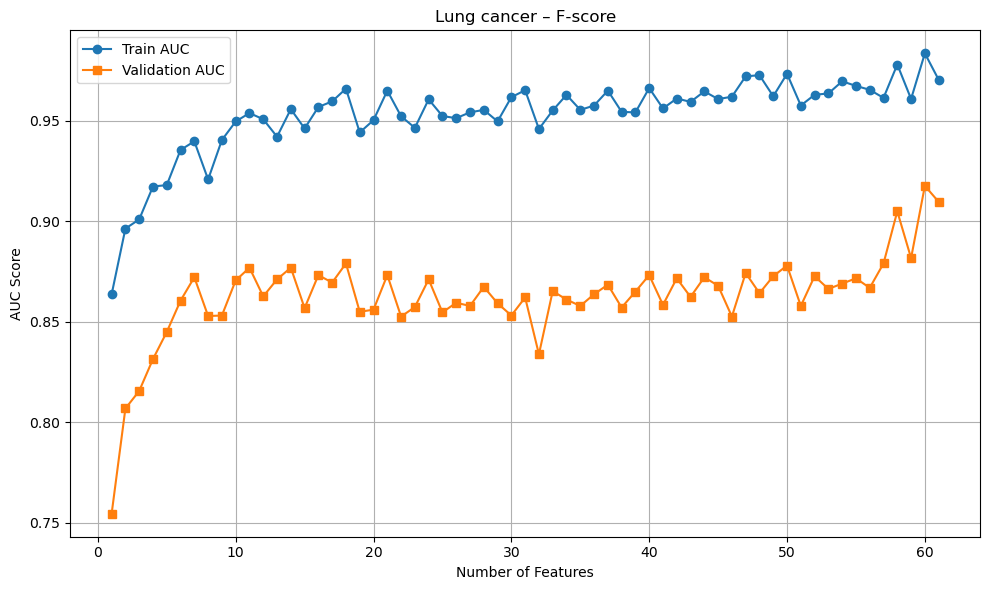

In [23]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_Fscore.csv")

# 绘制图像
plt.figure(figsize=(10, 6))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("Lung cancer – F-score")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_Fscore.png", dpi=300)
plt.show()


### ANOVA

In [10]:
import pandas as pd

# 1. 读取最终的 CSV 文件
csv_file = "Lung_sample_AnovaSorted.csv"
df = pd.read_csv(csv_file)

# 2. 读取 ANOVA 排序的特征文件，获取正确的特征名顺序
anova_sorted_file = "../ANOVA/Lung_feature_importance.csv" 
with open(anova_sorted_file, "r") as f:
    sorted_feature_names = [line.split()[1] for line in f.readlines()]  # 取出特征名称

# 3. 获取当前 CSV 文件的列名（去掉第一列 class）
original_column_names = list(df.columns[1:])  # 去掉第 1 列类别标签

# 4. 创建新的列名列表（保持类别标签不变）
new_column_names = ["class"] + sorted_feature_names[:len(original_column_names)]

# 5. 重新设置 DataFrame 的列名
df.columns = new_column_names

# 6. 保存修改后的 CSV 文件
df.to_csv("Lung_sample_AnovaSorted_corrected.csv", index=False)


In [25]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "Lung_sample_AnovaSorted_corrected.csv"
data = pd.read_csv(file_path)

In [26]:
data

,class,CNA_1:121000001-122000000,MOTIF_END_TCTG,MOTIF_END_CCCA,MOTIF_END_TAGA,MOTIF_END_CCCC,MOTIF_END_TCCC,MOTIF_END_CCCT,MOTIF_END_CCTG,MOTIF_END_TGCC,...,GWMD_chr13_35,GWMD_chr18_25,GWMD_chr4_75,GWFP_long_10:75000001-80000000,GWMD_chr10_29,GWMD_chr1_121,CNA_5:84000001-85000000,GWFP_short_6:140000001-145000000,CNA_14:39000001-40000000,GWMD_chr6_84
0,1,7.65144,0.005431,0.005640,0.005423,0.003046,0.002677,0.004431,0.008257,0.003282,...,0.835942,0.734699,0.799058,0.342765,0.744587,0.757877,0.946621,0.314483,0.999889,0.783371
1,1,4.76721,0.005945,0.005706,0.005328,0.003106,0.002661,0.004771,0.009367,0.003794,...,0.791275,0.693370,0.758242,0.056349,0.704685,0.759648,0.876217,0.059905,1.094550,0.750000
2,1,7.35850,0.005288,0.005182,0.005619,0.002783,0.002533,0.003980,0.007486,0.003156,...,0.808050,0.752156,0.783515,0.326200,0.755080,0.763684,0.955688,0.184310,0.987095,0.760370
3,1,5.78055,0.005137,0.005039,0.005805,0.002596,0.002355,0.003499,0.008427,0.002849,...,0.840815,0.719798,0.808779,0.264654,0.754910,0.823351,0.980302,0.052603,1.027590,0.770312
4,1,6.77078,0.005828,0.006348,0.004958,0.003622,0.002849,0.005208,0.009857,0.003716,...,0.821820,0.655213,0.761431,-0.041014,0.660067,0.677433,0.950739,0.028298,1.112230,0.740541
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
539,0,3.88667,0.005774,0.006031,0.005098,0.003233,0.002671,0.004489,0.009800,0.003355,...,0.797404,0.732219,0.746003,0.034222,0.722139,0.699089,0.912466,0.137908,1.100820,0.759036
540,0,5.50876,0.006160,0.006676,0.005082,0.003927,0.002910,0.005517,0.010330,0.003750,...,0.842505,0.764144,0.779553,0.141966,0.766169,0.773256,0.918819,0.089126,1.053150,0.752598
541,0,6.74441,0.005529,0.005476,0.005238,0.002993,0.002728,0.004425,0.007968,0.003499,...,0.841522,0.763596,0.789839,0.301025,0.765306,0.755292,0.926981,0.327066,1.036040,0.784262
542,0,4.85376,0.005528,0.005563,0.005410,0.003121,0.002669,0.004475,0.008596,0.003330,...,0.800458,0.677848,0.756530,0.250306,0.689810,0.712602,0.960959,0.210402,1.030170,0.753946


In [27]:
# 分层采样：拆分训练集和测试集，确保类别比例一致
train_data, test_data = train_test_split(
    data, test_size=0.2, random_state=42, stratify=data['class']
)
X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [32]:
all_features = X_train.columns.tolist()
auc_train_scores_ANOVA = []
auc_val_scores_ANOVA = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.1  
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 10
max_decline_tolerance = 5

In [33]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_ANOVA.append(auc_train)
    auc_val_scores_ANOVA.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >60:
        break
    
    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
过拟合检测：训练集 AUC=0.8636, 验证集 AUC=0.7545，连续次数：1
{2}
{3}
{4}
{5}
{6}
{7}
{8}
验证集 AUC 开始下降（0.8721 → 0.8528），连续次数：1
{9}
{10}
{11}
{12}
验证集 AUC 开始下降（0.8768 → 0.8626），连续次数：1
{13}
{14}
{15}
验证集 AUC 开始下降（0.8768 → 0.8568），连续次数：1
{16}
{17}
验证集 AUC 开始下降（0.8732 → 0.8695），连续次数：1
{18}
{19}
验证集 AUC 开始下降（0.8790 → 0.8549），连续次数：1
{20}
{21}
{22}
验证集 AUC 开始下降（0.8732 → 0.8525），连续次数：1
{23}
{24}
{25}
验证集 AUC 开始下降（0.8710 → 0.8547），连续次数：1
{26}
{27}
验证集 AUC 开始下降（0.8594 → 0.8578），连续次数：1
{28}
{29}
验证集 AUC 开始下降（0.8673 → 0.8591），连续次数：1
{30}
过拟合检测：训练集 AUC=0.9617, 验证集 AUC=0.8531，连续次数：1
验证集 AUC 开始下降（0.8591 → 0.8531），连续次数：2
{31}
过拟合检测：训练集 AUC=0.9651, 验证集 AUC=0.8621，连续次数：2
{32}
过拟合检测：训练集 AUC=0.9458, 验证集 AUC=0.8338，连续次数：3
验证集 AUC 开始下降（0.8621 → 0.8338），连续次数：1
{33}
{34}
过拟合检测：训练集 AUC=0.9628, 验证集 AUC=0.8610，连续次数：1
验证集 AUC 开始下降（0.8652 → 0.8610），连续次数：1
{35}
验证集 AUC 开始下降（0.8610 → 0.8578），连续次数：2
{36}
{37}
{38}
验证集 AUC 开始下降（0.8684 → 0.8570），连续次数：1
{39}
{40}
{41}
验证集 AUC 开始下降（0.8732 → 0.8584），连续次数：1
{42}
{43}
验证集 AUC 开始下降（0.8716

In [36]:
Lung_sample_AnovaSorted_corrected = pd.read_csv("Lung_sample_AnovaSorted_corrected.csv")
Lung_sample_AnovaSorted_selected60 = Lung_sample_AnovaSorted_corrected.iloc[:, :61]
Lung_sample_AnovaSorted_selected60.to_csv("../ANOVA/Lung_sample_AnovaSorted_selected60.csv", index=False)

In [34]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_ANOVA) + 1),
    "Train_AUC": auc_train_scores_ANOVA,
    "Validation_AUC": auc_val_scores_ANOVA
})

auc_df.to_csv("AUC_scores_ANOVA.csv", index=False)

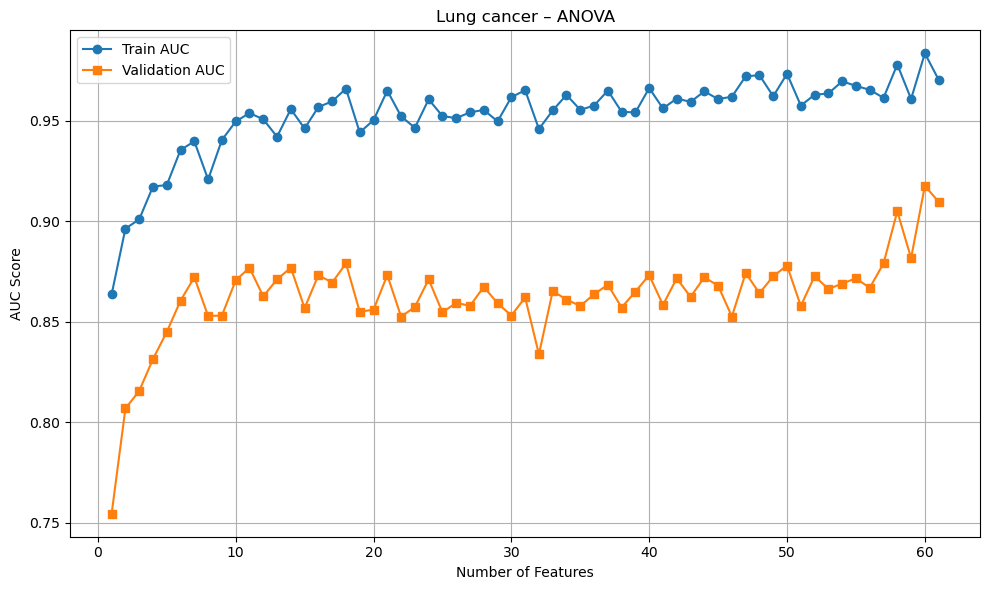

In [35]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_ANOVA.csv")

# 绘制图像
plt.figure(figsize=(10, 6))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("Lung cancer – ANOVA")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_ANOVA.png", dpi=300)
plt.show()


### ReliefF

In [37]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "Lung_sample_ReliefFSorted.csv"
data = pd.read_csv(file_path)

In [38]:
data


,class,MOTIF_END_TGCA,MOTIF_END_TGAT,MOTIF_END_TGAC,MOTIF_END_TGCC,MOTIF_END_TGCT,CNA_10:93000001-94000000,MOTIF_END_CAGT,MOTIF_END_CAGA,MOTIF_END_TGTT,...,GWFP_short_12:105000001-110000000,CNA_12:33000001-34000000,GWFP_short_12:30000001-35000000,CNA_12:129000001-130000000,CNA_12:32000001-33000000,CNA_1:13000001-14000000,CNA_14:89000001-90000000,CNA_14:91000001-92000000,TMD_269,CNA_14:90000001-91000000
0,1,0.004978,0.004708,0.003470,0.003282,0.004414,1.481670,0.005675,0.008750,0.006227,...,0.492192,1.032510,0.115129,1.057620,1.01554,1.120500,0.490951,0.508719,0.020202,0.523771
1,1,0.006043,0.005517,0.003818,0.003794,0.005457,0.746508,0.005703,0.009289,0.006905,...,0.401702,1.027000,-0.253784,1.077480,1.03033,0.859874,0.497695,0.533140,0.000000,0.550379
2,1,0.004918,0.004878,0.003461,0.003156,0.004349,1.510740,0.005665,0.008652,0.006346,...,0.610936,0.990174,-0.098437,1.051340,1.00703,1.157970,0.487636,0.512967,0.012048,0.506614
3,1,0.004587,0.004244,0.003238,0.002849,0.003786,2.417720,0.005970,0.009480,0.005479,...,0.425852,1.042740,-0.143125,1.024420,1.04185,1.007630,0.508654,0.506097,0.000000,0.537797
4,1,0.005275,0.004699,0.003509,0.003716,0.004815,1.027850,0.005445,0.008474,0.006077,...,0.407706,1.110530,-0.098721,1.081670,1.06109,0.879714,0.533628,0.551970,0.005263,0.544891
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
539,0,0.005166,0.004508,0.003542,0.003355,0.004462,1.063370,0.005663,0.008639,0.006085,...,0.363226,0.994949,-0.271659,1.102590,1.01531,0.876653,0.510261,0.514193,0.000000,0.530664
540,0,0.005501,0.005019,0.003729,0.003750,0.005059,1.733130,0.005458,0.008477,0.006667,...,0.468011,1.087340,-0.078961,0.991644,1.04486,0.890978,0.509316,0.505770,0.038462,0.544792
541,0,0.005290,0.004785,0.003514,0.003499,0.004824,1.411470,0.005392,0.008053,0.006322,...,0.517022,1.025620,0.274437,1.050390,1.04267,1.049770,0.493711,0.480363,0.000000,0.517156
542,0,0.005076,0.004563,0.003334,0.003330,0.004489,1.038630,0.005598,0.008549,0.006059,...,0.346606,0.993957,-0.262106,1.000270,1.00813,1.132070,0.517928,0.516820,0.021429,0.526078


In [39]:
# 分层采样：拆分训练集和测试集，确保类别比例一致
train_data, test_data = train_test_split(
    data, test_size=0.2, random_state=42, stratify=data['class']
)
X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [44]:
all_features = X_train.columns.tolist()
auc_train_scores_ReliefF = []
auc_val_scores_ReliefF = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.2
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 10
max_decline_tolerance = 5

In [45]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_ReliefF.append(auc_train)
    auc_val_scores_ReliefF.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >150:
        break
    
    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
{2}
{3}
{4}
验证集 AUC 开始下降（0.8428 → 0.8399），连续次数：1
{5}
验证集 AUC 开始下降（0.8399 → 0.8097），连续次数：2
{6}
{7}
验证集 AUC 开始下降（0.8192 → 0.8050），连续次数：1
{8}
验证集 AUC 开始下降（0.8050 → 0.8018），连续次数：2
{9}
{10}
验证集 AUC 开始下降（0.8377 → 0.8351），连续次数：1
{11}
验证集 AUC 开始下降（0.8351 → 0.8264），连续次数：2
{12}
{13}
验证集 AUC 开始下降（0.8351 → 0.8319），连续次数：1
{14}
{15}
{16}
验证集 AUC 开始下降（0.8562 → 0.8309），连续次数：1
{17}
{18}
验证集 AUC 开始下降（0.8393 → 0.8272），连续次数：1
{19}
{20}
验证集 AUC 开始下降（0.8684 → 0.8317），连续次数：1
{21}
验证集 AUC 开始下降（0.8317 → 0.8227），连续次数：2
{22}
{23}
验证集 AUC 开始下降（0.8473 → 0.8399），连续次数：1
{24}
{25}
验证集 AUC 开始下降（0.8441 → 0.8372），连续次数：1
{26}
{27}
验证集 AUC 开始下降（0.8467 → 0.8261），连续次数：1
{28}
验证集 AUC 开始下降（0.8261 → 0.8235），连续次数：2
{29}
{30}
{31}
验证集 AUC 开始下降（0.8531 → 0.8346），连续次数：1
{32}
验证集 AUC 开始下降（0.8346 → 0.8232），连续次数：2
{33}
{34}
{35}
验证集 AUC 开始下降（0.8552 → 0.8335），连续次数：1
{36}
{37}
验证集 AUC 开始下降（0.8565 → 0.8531），连续次数：1
{38}
{39}
验证集 AUC 开始下降（0.8689 → 0.8499），连续次数：1
{40}
验证集 AUC 开始下降（0.8499 → 0.8422），连续次数：2
{41}
验证集 AUC 开始下降（0.8422 → 0.829

In [48]:
Lung_sample_ReliefFSorted = pd.read_csv("Lung_sample_ReliefFSorted.csv")
Lung_sample_ReliefFSorted_selected91 = Lung_sample_ReliefFSorted.iloc[:, :92]
Lung_sample_ReliefFSorted_selected91.to_csv("../ReliefF/Lung_sample_ReliefFSorted_selected91.csv", index=False)

In [46]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_ReliefF) + 1),
    "Train_AUC": auc_train_scores_ReliefF,
    "Validation_AUC": auc_val_scores_ReliefF
})

auc_df.to_csv("AUC_scores_ReliefF.csv", index=False)

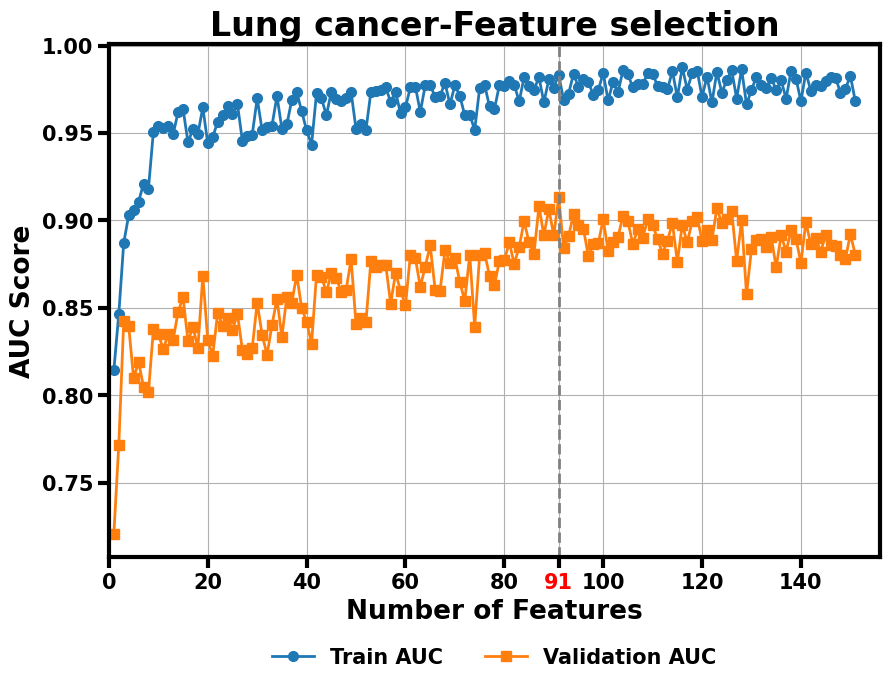

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_ReliefF.csv")

# 绘制图像
plt.figure(figsize=(9, 7))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o', linewidth=2, markersize=7)
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s', linewidth=2, markersize=7)

plt.xlabel("Number of Features", fontsize=19, fontweight='bold')
plt.ylabel("AUC Score", fontsize=19, fontweight='bold')
plt.title("Lung cancer-Feature selection", fontsize=24, fontweight='bold')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False, prop={'family': 'sans-serif', 'size': 15, 'weight': 'bold'})
plt.grid(True)

# 添加竖线标注特征数 = 91
plt.axvline(x=91, color='gray', linestyle='--', linewidth=2)

# 设置 x 轴刻度并强制包含 91
xticks = sorted(set(plt.xticks()[0].tolist() + [91]))
plt.xticks(xticks)

# 获取坐标轴并标红 91
ax = plt.gca()
for label in ax.get_xticklabels():
    if label.get_text() == '91':
        label.set_color('red')

ax.set_xlim(left=0, right=max(auc_df["Num_Features"]) + 5)

ax = plt.gca()  # 获取当前坐标轴
for spine in ax.spines.values():
    spine.set_linewidth(3)
ax.tick_params(axis='both', width=3, length=8)
for tick_label in ax.get_xticklabels() + ax.get_yticklabels():
    tick_label.set_fontsize(15)
    tick_label.set_fontweight('bold')

# 保存图像为 PNG 文件
plt.tight_layout()
plt.savefig("AUC_vs_FeatureCount_ReliefF.png", dpi=300)
plt.show()


### Binomial

In [50]:
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import metrics
import matplotlib.pyplot as plt

file_path = "Lung_sample_BinomialSorted.csv"
data = pd.read_csv(file_path)

In [51]:
data

,class,TMD_10,TMD_98,CNA_12:69000001-70000000,TMD_99,TMD_317,GWMD_chr16_27,CNA_1:13000001-14000000,TMD_101,TMD_351,...,GWFP_short_6:140000001-145000000,GWFP_total_2:170000001-175000000,GWFP_total_11:85000001-90000000,GWMD_chr2_224,CNA_3:86000001-87000000,CNA_9:98000001-99000000,GWFP_long_12:50000001-55000000,GWFP_short_9:105000001-110000000,GWFP_total_8:120000001-125000000,CNA_9:131000001-132000000
0,1,0.011745,0.000000,1.042310,0.074152,0.027658,0.804914,1.120500,0.011933,0.004754,...,0.314483,0.533333,-0.118080,0.673108,1.020900,0.829726,0.292361,0.308787,0.611475,0.962597
1,1,0.005556,0.000000,1.019140,0.030457,0.007246,0.723788,0.859874,0.018405,0.008000,...,0.059905,0.494942,-0.148085,0.591124,0.994971,0.886840,0.265915,-0.032290,0.543124,0.868522
2,1,0.014652,0.015444,1.020840,0.079295,0.089888,0.723792,1.157970,0.032511,0.003390,...,0.184310,0.621418,-0.257406,0.678540,0.969824,0.905631,0.267368,0.015378,0.637557,0.945353
3,1,0.013347,0.000000,1.036280,0.039578,0.019355,0.789765,1.007630,0.021762,0.017241,...,0.052603,0.541690,-0.130334,0.620683,0.956175,0.865834,0.277038,0.009361,0.567780,0.878492
4,1,0.008083,0.000000,1.118300,0.008499,0.023392,0.818971,0.879714,0.006470,0.016216,...,0.028298,0.488445,-0.105706,0.558923,0.995953,0.929985,0.207475,-0.143260,0.533720,0.871316
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
539,0,0.000000,0.000000,0.960918,0.024896,0.013423,0.800527,0.876653,0.491803,0.000000,...,0.137908,0.399925,-0.147403,0.640365,0.994090,1.088730,0.146284,0.166766,0.538049,0.899353
540,0,0.018182,0.000000,0.995361,0.000000,0.020548,0.817804,0.890978,0.004073,0.000000,...,0.089126,0.556037,-0.193388,0.661130,0.952300,0.935691,0.295723,0.133214,0.512500,0.944801
541,0,0.017895,0.000000,1.028150,0.010504,0.020067,0.806923,1.049770,0.009764,0.020408,...,0.327066,0.553341,-0.198108,0.707376,0.976822,0.842960,0.318086,0.196317,0.686063,0.952025
542,0,0.005236,0.000000,1.005920,0.084210,0.008989,0.795361,1.132070,0.005115,0.019418,...,0.210402,0.629358,-0.131695,0.651930,1.006860,0.875111,0.342078,0.225536,0.676826,0.960381


In [52]:
# 分层采样：拆分训练集和测试集，确保类别比例一致
train_data, test_data = train_test_split(
    data, test_size=0.2, random_state=42, stratify=data['class']
)
X_train = train_data.drop(columns=["class"])    # 训练特征
y_train = train_data["class"]  # 训练标签
X_test = test_data.drop(columns=["class"])  # 测试特征
y_test = test_data["class"]  # 测试标签

X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

In [61]:
all_features = X_train.columns.tolist()
auc_train_scores_Binomial = []
auc_val_scores_Binomial = []
best_auc = 0
best_feature_count = 0
best_X_train = None
best_X_test = None
best_X_val = None
prev_val_auc = 0
max_auc_diff = 0.25
for_num = 0

# 连续超过阈值的计数器
overfit_count = 0
decline_count = 0

# 设置连续次数阈值
max_overfit_tolerance = 30
max_decline_tolerance = 5

In [62]:

# 从无特征开始，逐步添加特征
for i in range(1, len(all_features) + 1):
    selected_features = all_features[:i]  # 取前 i 个特征
    
    # 构造训练数据
    dtrain = xgb.DMatrix(X_train[selected_features], label=y_train)
    dval = xgb.DMatrix(X_val[selected_features], label=y_val)
    dtest = xgb.DMatrix(X_test[selected_features], label=y_test)
    
    # XGBoost 参数
    params = {
        'booster': 'gbtree',
        'objective': 'binary:logistic',
        'eval_metric': 'auc',
        'max_depth': 4,
        'lambda': 3,
        'alpha': 0.2,
        'subsample': 0.75,
        'colsample_bytree': 0.75,
        'min_child_weight': 6,
        'eta': 0.025,
        'seed': 0,
        'nthread': 8,
        'gamma': 0.2,
        'learning_rate': 0.05
    }
    
    watchlist = [(dtrain, 'train'), (dval, 'eval')]
    
    # 训练模型
    model = xgb.train(params, dtrain, num_boost_round=50, evals=watchlist, early_stopping_rounds=10, verbose_eval=False)
    
    # 计算 AUC
    y_pred_train = model.predict(dtrain)
    y_pred_val = model.predict(dval)
    
    auc_train = roc_auc_score(y_train, y_pred_train)
    auc_val = roc_auc_score(y_val, y_pred_val)
    
    auc_train_scores_Binomial.append(auc_train)
    auc_val_scores_Binomial.append(auc_val)

    for_num += 1
    print({for_num})

    if for_num >60:
        break

    # 过拟合判断
    if (auc_train - auc_val) > max_auc_diff:
        overfit_count += 1
        print(f"过拟合检测：训练集 AUC={auc_train:.4f}, 验证集 AUC={auc_val:.4f}，连续次数：{overfit_count}")
        if overfit_count >= max_overfit_tolerance:
            print(f"过拟合连续超过 {max_overfit_tolerance} 次，停止特征增加！")
            break
    else:
        overfit_count = 0

    # 验证集 AUC 下降判断
    if auc_val < prev_val_auc:
        decline_count += 1
        print(f"验证集 AUC 开始下降（{prev_val_auc:.4f} → {auc_val:.4f}），连续次数：{decline_count}")
        if decline_count >= max_decline_tolerance:
            print(f"验证集 AUC 连续下降超过 {max_decline_tolerance} 次，停止特征增加！")
            break
    else:
        decline_count = 0

   # 记录当前最优特征集
    if auc_val > best_auc:
        best_auc = auc_val
        train_p = auc_train
        best_feature_count = i
        best_X_train = X_train[selected_features].copy()
        best_X_test = X_test[selected_features].copy()
        best_X_val = X_val[selected_features].copy()
        
    # 记录上一次的验证集 AUC
    prev_val_auc = auc_val

# 输出最佳特征数
print(f"选择的特征数: {best_feature_count}, 最佳验证集 AUC: {best_auc:.4f}, 对应的训练集 AUC：{train_p:.4f}")

{1}
{2}
{3}
{4}
验证集 AUC 开始下降（0.8221 → 0.8124），连续次数：1
{5}
{6}
{7}
{8}
{9}
{10}
验证集 AUC 开始下降（0.8784 → 0.8753），连续次数：1
{11}
{12}
验证集 AUC 开始下降（0.8805 → 0.8726），连续次数：1
{13}
验证集 AUC 开始下降（0.8726 → 0.8668），连续次数：2
{14}
验证集 AUC 开始下降（0.8668 → 0.8663），连续次数：3
{15}
验证集 AUC 开始下降（0.8663 → 0.8510），连续次数：4
{16}
{17}
{18}
{19}
{20}
验证集 AUC 开始下降（0.8811 → 0.8737），连续次数：1
{21}
{22}
{23}
验证集 AUC 开始下降（0.8959 → 0.8842），连续次数：1
{24}
{25}
验证集 AUC 开始下降（0.8906 → 0.8901），连续次数：1
{26}
{27}
验证集 AUC 开始下降（0.8990 → 0.8874），连续次数：1
{28}
{29}
验证集 AUC 开始下降（0.8906 → 0.8842），连续次数：1
{30}
{31}
{32}
验证集 AUC 开始下降（0.8953 → 0.8901），连续次数：1
{33}
{34}
验证集 AUC 开始下降（0.8985 → 0.8932），连续次数：1
{35}
{36}
{37}
验证集 AUC 开始下降（0.9022 → 0.8959），连续次数：1
{38}
验证集 AUC 开始下降（0.8959 → 0.8943），连续次数：2
{39}
验证集 AUC 开始下降（0.8943 → 0.8737），连续次数：3
{40}
{41}
{42}
{43}
验证集 AUC 开始下降（0.9133 → 0.8985），连续次数：1
{44}
{45}
验证集 AUC 开始下降（0.9128 → 0.8700），连续次数：1
{46}
{47}
{48}
{49}
{50}
{51}
验证集 AUC 开始下降（0.9112 → 0.8964），连续次数：1
{52}
验证集 AUC 开始下降（0.8964 → 0.8784），连续次数：2
{53}
{54}

In [63]:
Lung_sample_BinomialSorted = pd.read_csv("Lung_sample_BinomialSorted.csv")
Lung_sample_BinomialSorted_selected42 = Lung_sample_BinomialSorted.iloc[:, :43]
Lung_sample_BinomialSorted_selected42.to_csv("../Binomial/Lung_sample_BinomialSorted_selected42.csv", index=False)

In [59]:
import pandas as pd

# 保存训练集和验证集的 AUC 到 CSV
auc_df = pd.DataFrame({
    "Num_Features": range(1, len(auc_train_scores_Binomial) + 1),
    "Train_AUC": auc_train_scores_Binomial,
    "Validation_AUC": auc_val_scores_Binomial
})

auc_df.to_csv("AUC_scores_Binomial.csv", index=False)

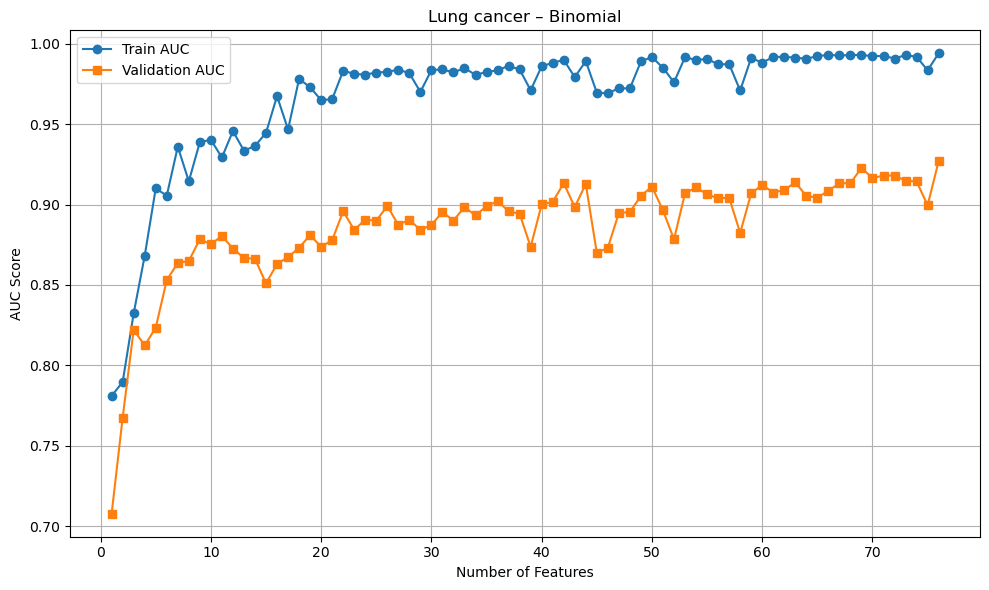

In [60]:
import matplotlib.pyplot as plt
import pandas as pd

# 读取 CSV 文件
auc_df = pd.read_csv("AUC_scores_Binomial.csv")

# 绘制图像
plt.figure(figsize=(10, 6))
plt.plot(auc_df["Num_Features"], auc_df["Train_AUC"], label='Train AUC', marker='o')
plt.plot(auc_df["Num_Features"], auc_df["Validation_AUC"], label='Validation AUC', marker='s')

plt.xlabel("Number of Features")
plt.ylabel("AUC Score")
plt.title("Lung cancer – Binomial")
plt.legend()
plt.grid(True)
plt.tight_layout()

# 保存图像为 PNG 文件
plt.savefig("AUC_vs_FeatureCount_Binomial.png", dpi=300)
plt.show()

### biomaker分析

In [2]:
import pandas as pd

file_paths = [
    "../ANOVA/Lung_sample_AnovaSorted_selected60.csv",
    "../Binomial/Lung_sample_BinomialSorted_selected42.csv",
    "../Fscore/Lung_sample_FscoreSorted_selected60.csv",
    "../ReliefF/Lung_sample_ReliefFSorted_selected91.csv"
]
dfs = [pd.read_csv(file_path) for file_path in file_paths]
dfs_info = [df.head() for df in dfs]


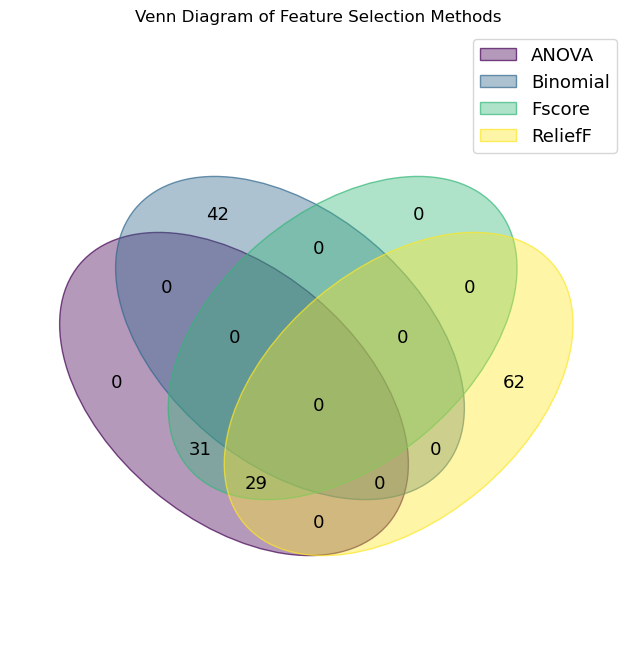

In [3]:
import matplotlib.pyplot as plt
from venn import venn
import pandas as pd

# 加载所有文件
df_anova = dfs[0]
df_binomial = dfs[1]
df_fscore = dfs[2]
df_reliefF = dfs[3]

# 提取每个文件的特征列
anova_features = set(df_anova.columns[1:])
binomial_features = set(df_binomial.columns[1:])
fscore_features = set(df_fscore.columns[1:])
relieff_features = set(df_reliefF.columns[1:])

feature_sets = {
    'ANOVA': anova_features,
    'Binomial': binomial_features,
    'Fscore': fscore_features,
    'ReliefF': relieff_features
}

venn(feature_sets)
plt.title("Venn Diagram of Feature Selection Methods")
plt.show()